# Data loading and Exploration

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [34]:
df = pd.read_csv("../../data/raw/telco_customer_churn.csv")

In [35]:
df.head(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [36]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,3186-AJIEK,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [37]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [38]:
df["TotalCharges"].info()

<class 'pandas.core.series.Series'>
RangeIndex: 7043 entries, 0 to 7042
Series name: TotalCharges
Non-Null Count  Dtype 
--------------  ----- 
7043 non-null   object
dtypes: object(1)
memory usage: 55.2+ KB


In [39]:
df["TotalCharges"] = df["TotalCharges"].replace(" ", np.nan)
df["TotalCharges"] = df["TotalCharges"].astype(float)
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())

In [40]:
df["TotalCharges"].value_counts()

TotalCharges
20.200      11
1397.475    11
19.750       9
19.650       8
19.900       8
            ..
1990.500     1
7362.900     1
346.450      1
306.600      1
108.150      1
Name: count, Length: 6531, dtype: int64

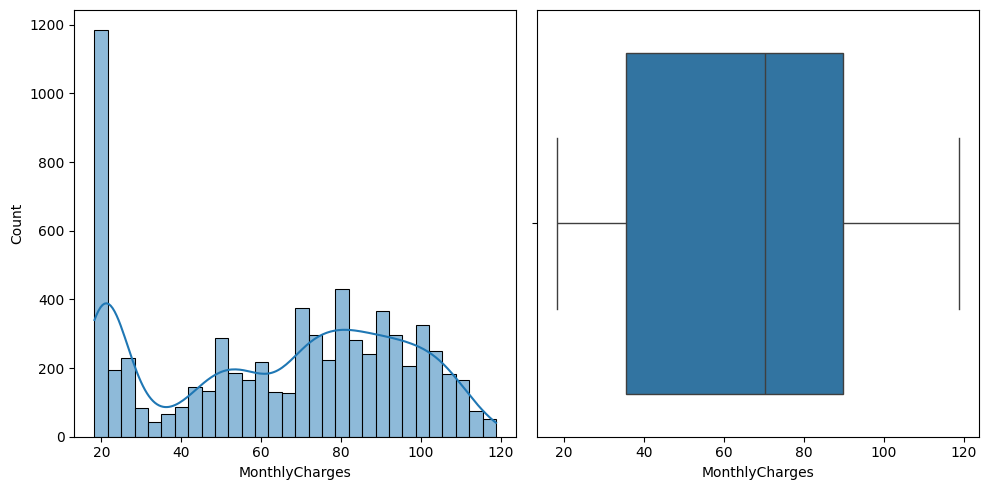

In [41]:
fig, axes = plt.subplots(1, 2, figsize = (10,5))

sns.histplot(data=df, x = "MonthlyCharges", bins=30, kde=True, ax=axes[0])
sns.boxplot(data=df, x = "MonthlyCharges", ax=axes[1])

plt.tight_layout()
plt.show()

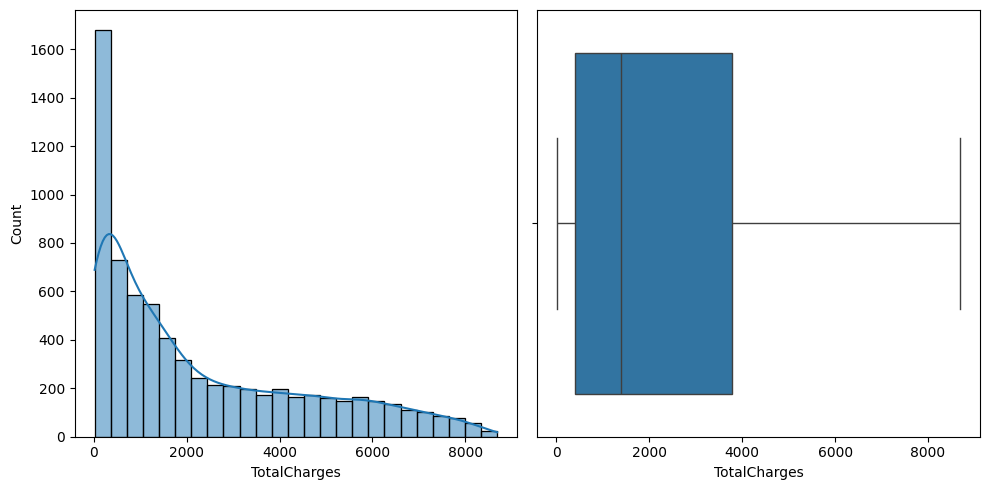

In [42]:
fig, axes = plt.subplots(1, 2, figsize = (10, 5))

sns.histplot(data = df, x = "TotalCharges", kde=True, ax = axes[0])
sns.boxplot(data=df, x = "TotalCharges", ax=axes[1])

plt.tight_layout()
plt.show()

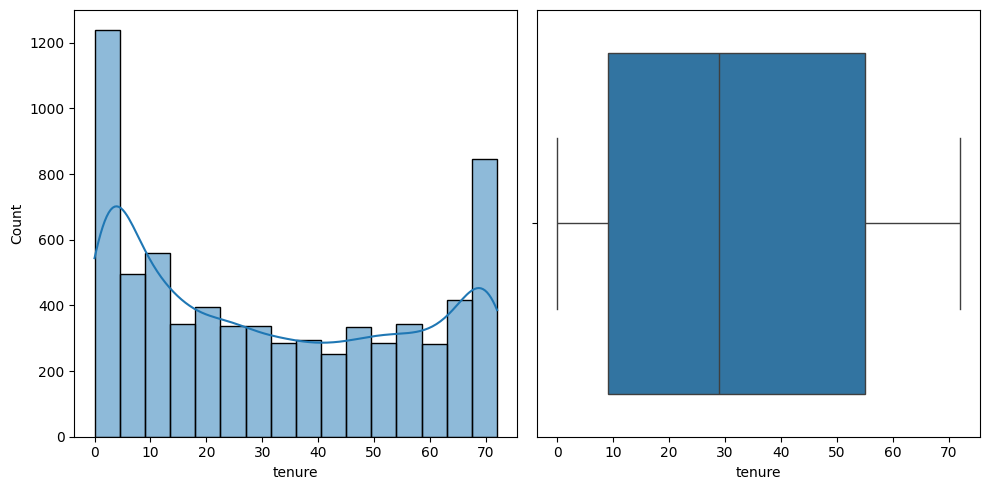

In [43]:
fig, axes = plt.subplots(1, 2 , figsize = (10, 5))

sns.histplot(data = df, x = "tenure", kde=True, ax=axes[0])
sns.boxplot(data = df, x = "tenure", ax=axes[1])

plt.tight_layout()

plt.show()

## Preprocessing

In [44]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer

encoder = OneHotEncoder()

binary_cols = ["gender", "Partner", "Dependents", "PhoneService", "PaperlessBilling", "Churn"]
categorical_cols = ["MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
                    "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
                    "Contract", "PaymentMethod"]

def binary_cols_transform(dataframe):
    return dataframe.replace({
        "Yes": 1, "No": 0,
        "Male": 1, "Female": 0
    }).astype(int)

In [45]:
df = df.drop("customerID", axis = 1)

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_cols),
        ("binary", FunctionTransformer(binary_cols_transform, feature_names_out="one-to-one"), binary_cols)
    ], 
    remainder="passthrough",
    verbose_feature_names_out=False
    )

In [46]:
df_transformed = preprocessor.fit_transform(df)
df_transformed = pd.DataFrame(
    df_transformed,
    columns=preprocessor.get_feature_names_out()
)

df_transformed = df_transformed.apply(pd.to_numeric)

C:\Users\zoran\AppData\Local\Temp\ipykernel_2344\3677533175.py:13: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return dataframe.replace({


In [47]:
df_transformed.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 31 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   MultipleLines_No phone service         7043 non-null   float64
 1   MultipleLines_Yes                      7043 non-null   float64
 2   InternetService_Fiber optic            7043 non-null   float64
 3   InternetService_No                     7043 non-null   float64
 4   OnlineSecurity_No internet service     7043 non-null   float64
 5   OnlineSecurity_Yes                     7043 non-null   float64
 6   OnlineBackup_No internet service       7043 non-null   float64
 7   OnlineBackup_Yes                       7043 non-null   float64
 8   DeviceProtection_No internet service   7043 non-null   float64
 9   DeviceProtection_Yes                   7043 non-null   float64
 10  TechSupport_No internet service        7043 non-null   float64
 11  Tech

In [48]:
float_cols = df_transformed.select_dtypes(include="float64").columns

binary_float_cols = [
    col for col in float_cols if df_transformed[col].isin([0.0, 1.0]).all()
]

df_transformed[binary_float_cols] = df_transformed[binary_float_cols].astype(int)

## Cleaning & VIF

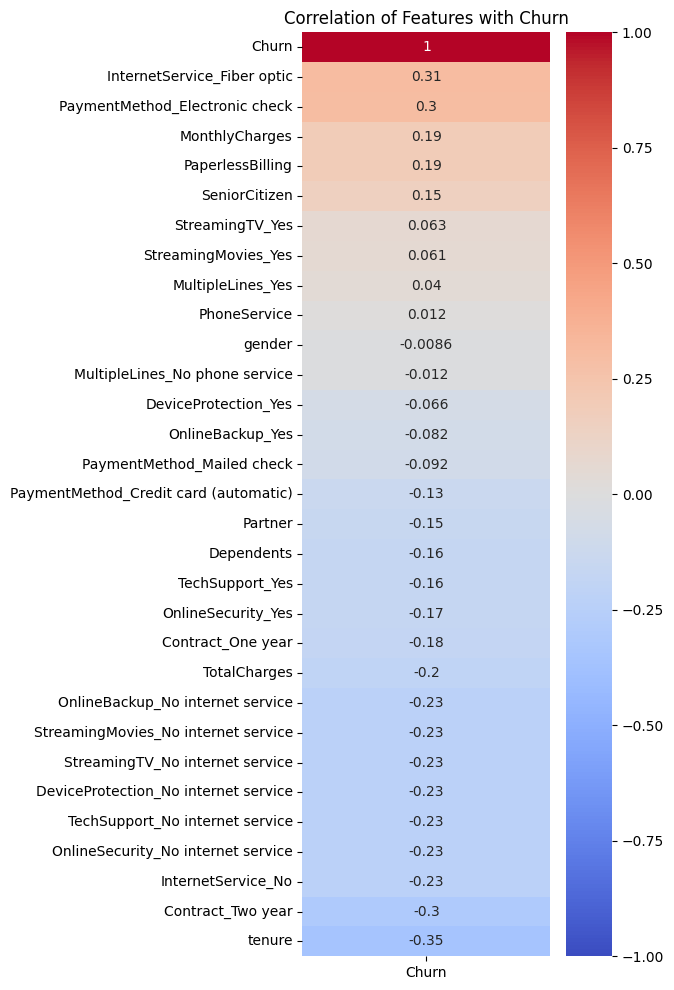

In [49]:
corr_df = df_transformed.corr(numeric_only=True)

churn_corr = corr_df[["Churn"]].sort_values(by="Churn", ascending=False)

plt.figure(figsize=(4,12))
sns.heatmap(data=churn_corr, cmap="coolwarm", annot=True, vmin=-1, vmax=1)
plt.title("Correlation of Features with Churn")
plt.show()

In [50]:
drop_cols = [
    col for col in df_transformed.columns
    if "No internet service" in col
    or "No phone service" in col
]

df_transformed = df_transformed.drop(columns=drop_cols)

In [51]:
df_transformed.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 24 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   MultipleLines_Yes                      7043 non-null   int64  
 1   InternetService_Fiber optic            7043 non-null   int64  
 2   InternetService_No                     7043 non-null   int64  
 3   OnlineSecurity_Yes                     7043 non-null   int64  
 4   OnlineBackup_Yes                       7043 non-null   int64  
 5   DeviceProtection_Yes                   7043 non-null   int64  
 6   TechSupport_Yes                        7043 non-null   int64  
 7   StreamingTV_Yes                        7043 non-null   int64  
 8   StreamingMovies_Yes                    7043 non-null   int64  
 9   Contract_One year                      7043 non-null   int64  
 10  Contract_Two year                      7043 non-null   int64  
 11  Paym

In [52]:
X = df_transformed.drop("Churn", axis=1)
bool_cols = X.select_dtypes(include="bool").columns
X[bool_cols] = X[bool_cols].astype(int)

In [53]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [54]:
X = X.replace([np.inf, -np.inf], np.nan)
X = X.dropna()

vif_data = pd.DataFrame()
vif_data["feature"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
vif_data = vif_data.sort_values(by="VIF", ascending=False)

print(vif_data)

                                  feature         VIF
21                         MonthlyCharges  865.066041
1             InternetService_Fiber optic  148.263438
2                      InternetService_No  104.219371
17                           PhoneService   34.861870
8                     StreamingMovies_Yes   24.109793
7                         StreamingTV_Yes   24.056872
22                           TotalCharges   10.675411
20                                 tenure    7.407607
0                       MultipleLines_Yes    7.274160
5                    DeviceProtection_Yes    6.922501
4                        OnlineBackup_Yes    6.783323
6                         TechSupport_Yes    6.467578
3                      OnlineSecurity_Yes    6.336238
10                      Contract_Two year    2.628609
12         PaymentMethod_Electronic check    1.976212
13             PaymentMethod_Mailed check    1.860564
9                       Contract_One year    1.621968
11  PaymentMethod_Credit car

## Machine learning

In [55]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [56]:
y = df_transformed["Churn"]
y.info()

<class 'pandas.core.series.Series'>
RangeIndex: 7043 entries, 0 to 7042
Series name: Churn
Non-Null Count  Dtype
--------------  -----
7043 non-null   int64
dtypes: int64(1)
memory usage: 55.2 KB


In [57]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

THRESHOLD = 0.3

### RandomForest Classifier

In [58]:
randomforest = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

randomforest.fit(X_train, y_train)

proba = randomforest.predict_proba(X_test)[:,1]
y_pred = (proba >= THRESHOLD).astype(int)

print(classification_report(y_test, y_pred, digits=3))

              precision    recall  f1-score   support

           0      0.886     0.757     0.816      1035
           1      0.520     0.730     0.607       374

    accuracy                          0.749      1409
   macro avg      0.703     0.743     0.712      1409
weighted avg      0.789     0.749     0.761      1409



### LightGBM classifier

In [61]:
from lightgbm import LGBMClassifier

ModuleNotFoundError: No module named 'lightgbm'

### XGBoost Classifier